# Dependency graph and reference path

Load the validated `real_v1` graph, inspect its weights and plot the ideal response to a 20% WTI increase. The real graph and processed market inputs must be prepared before running this notebook.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from marketsim.data import api
from marketsim.graph import load_graph
from marketsim.graph.reference import reference_path
from marketsim.graph.scenarios import build_real_2024_2025

graph = load_graph("real_v1")
graph.validate()
print(f"Companies: {len(graph.companies())}; full spectral radius: {graph.spectral_radius('full'):.4f}")

Companies: 18; full spectral radius: 0.0000


## Graph and edge-weight table

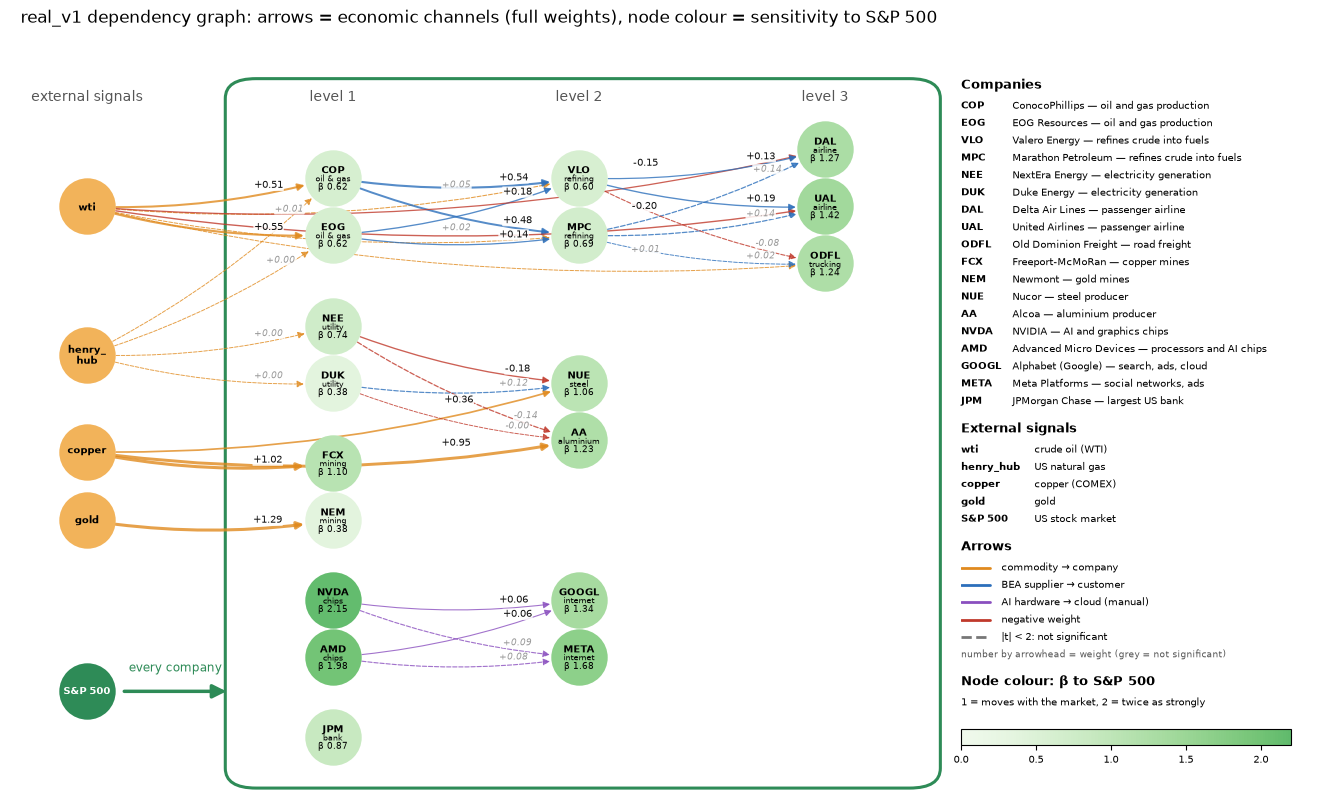

,parent,child,w_direct,w_full,t_stat_direct,t_stat_full,source,justification
0,wti,COP,0.514614,0.514614,20.2979,20.2979,commodity,Crude oil exploration and production revenue d...
1,henry_hub,COP,0.005580,0.005580,0.7713,0.7713,commodity,Natural gas co-production revenue of upstream ...
2,sp500,COP,0.616778,0.616778,10.8865,10.8865,index,Common US equity market factor (S&P 500)
3,wti,EOG,0.552229,0.552229,18.8850,18.8850,commodity,Crude oil exploration and production revenue d...
4,henry_hub,EOG,0.004285,0.004285,0.5137,0.5137,commodity,Natural gas co-production revenue of upstream ...
5,sp500,EOG,0.620723,0.620723,9.4992,9.4992,index,Common US equity market factor (S&P 500)
6,wti,VLO,0.429949,0.053988,14.1257,1.7470,commodity,Crude oil is the primary feedstock of petroleu...
7,sp500,VLO,0.602782,0.158980,8.8595,2.6853,index,Common US equity market factor (S&P 500)
8,COP,VLO,NaN,0.538254,NaN,9.2814,bea,BEA 2023: petroleum refining (324) spends 50.8...
9,EOG,VLO,NaN,0.177971,NaN,3.5387,bea,BEA 2023: petroleum refining (324) spends 50.8...


In [2]:
import matplotlib
from matplotlib import colors as mcolors
from matplotlib.patches import FancyBboxPatch

weights = pd.DataFrame([
    {"parent": e.parent, "child": e.child, "w_direct": e.w_direct,
     "w_full": e.w_full, "t_stat_direct": e.t_stat_direct,
     "t_stat_full": e.t_stat_full, "source": e.source,
     "justification": e.justification}
    for e in graph.edges
])
edges = weights
external_nodes = graph.externals()  # also used by the reference-wave cell below

# Layout: external signals on the left, companies in columns by their depth in the company chains.
# S&P 500 -> every company is shown once (arrow into the frame); node colour encodes the direct beta.
externals = ["wti", "henry_hub", "copper", "gold"]
companies = {  # ticker: (name, short sector, description)
    "COP": ("ConocoPhillips", "oil & gas", "oil and gas production"),
    "EOG": ("EOG Resources", "oil & gas", "oil and gas production"),
    "VLO": ("Valero Energy", "refining", "refines crude into fuels"),
    "MPC": ("Marathon Petroleum", "refining", "refines crude into fuels"),
    "NEE": ("NextEra Energy", "utility", "electricity generation"),
    "DUK": ("Duke Energy", "utility", "electricity generation"),
    "DAL": ("Delta Air Lines", "airline", "passenger airline"),
    "UAL": ("United Airlines", "airline", "passenger airline"),
    "ODFL": ("Old Dominion Freight", "trucking", "road freight"),
    "FCX": ("Freeport-McMoRan", "mining", "copper mines"),
    "NEM": ("Newmont", "mining", "gold mines"),
    "NUE": ("Nucor", "steel", "steel producer"),
    "AA": ("Alcoa", "aluminium", "aluminium producer"),
    "NVDA": ("NVIDIA", "chips", "AI and graphics chips"),
    "AMD": ("Advanced Micro Devices", "chips", "processors and AI chips"),
    "GOOGL": ("Alphabet (Google)", "internet", "search, ads, cloud"),
    "META": ("Meta Platforms", "internet", "social networks, ads"),
    "JPM": ("JPMorgan Chase", "bank", "largest US bank"),
}
signals = {"wti": "crude oil (WTI)", "henry_hub": "US natural gas", "copper": "copper (COMEX)",
           "gold": "gold", "S&P 500": "US stock market"}
rows = {0: externals, 1: ["COP", "EOG", "NEE", "DUK", "FCX", "NEM", "NVDA", "AMD", "JPM"],
        2: ["VLO", "MPC", "NUE", "AA", "GOOGL", "META"], 3: ["DAL", "UAL", "ODFL"]}
y_of = {"COP": 0, "EOG": 1, "NEE": 2.6, "DUK": 3.6, "FCX": 5, "NEM": 6, "NVDA": 7.4, "AMD": 8.4, "JPM": 9.8,
        "VLO": 0, "MPC": 1, "NUE": 3.6, "AA": 4.6, "GOOGL": 7.4, "META": 8.4, "DAL": -0.5, "UAL": 0.5, "ODFL": 1.5,
        "wti": 0.5, "henry_hub": 3.1, "copper": 4.8, "gold": 6}
K = 1.15  # vertical spacing
NODE = 1650  # marker area, the same for every node
pos = {n: (d * 3.2, -K * y_of[n]) for d, ns in rows.items() for n in ns}
pos["sp500"] = (0, -K * 9.0)
# Direct beta: market sensitivity with only external parents (the full beta is shrunk by company parents).
beta = edges[edges.source == "index"].set_index("child").w_direct
col = {"commodity": "#e08a1e", "bea": "#2c6fbb", "manual": "#8a4fbf", "negative": "#c0392b"}
norm = mcolors.Normalize(0, 2.2)
# Light part of "Greens" only, so black labels stay readable on every node.
cmap = mcolors.ListedColormap(matplotlib.colormaps["Greens"](np.linspace(0.05, 0.55, 256)))

fig = plt.figure(figsize=(17, 9.6))
gs = fig.add_gridspec(1, 2, width_ratios=[3.2, 1.25], wspace=0.02)
ax = fig.add_subplot(gs[0]); side = fig.add_subplot(gs[1])

FRAME_TOP = 1.9 + 0.1  # box top + boxstyle pad, in data units
ax.add_patch(FancyBboxPatch((1.9, -K * 10.0 - 0.7), 9.1, K * 10.0 + 2.6, boxstyle="round,pad=0.1,rounding_size=0.4",
                            fc="none", ec="#2e8b57", lw=2.2, zorder=0, clip_on=False))
ax.annotate("", xy=(1.85, -K * 9.0), xytext=(0.45, -K * 9.0),
            arrowprops=dict(arrowstyle="-|>", color="#2e8b57", lw=2.5, mutation_scale=20))
ax.text(1.15, -K * 9.0 + 0.4, "every company", ha="center", fontsize=8.5, color="#2e8b57")

for e in edges[edges.source != "index"].itertuples():
    (x0, y0), (x1, y1) = pos[e.parent], pos[e.child]; w = e.w_full
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(
        arrowstyle="-|>", color=col["negative"] if w < 0 else col[e.source], lw=0.7 + 1.5 * min(abs(w), 1.0),
        alpha=0.8, shrinkA=21, shrinkB=21, linestyle="--" if abs(e.t_stat_full) < 2 else "-",
        connectionstyle="arc3,rad=0.08"))
    # Label next to the arrowhead, so each number sits by the company it points to;
    # arrows that skip levels get their label further back to avoid stacking.
    length = np.hypot(x1 - x0, y1 - y0)
    back = 0.85 + 0.75 * (round(abs(x1 - x0) / 3.2) - 1)
    lx, ly = x1 - (x1 - x0) / length * back, y1 - (y1 - y0) / length * back
    significant = abs(e.t_stat_full) >= 2
    ax.text(lx, ly, f"{w:+.2f}", fontsize=7 if significant else 6.3, ha="center", va="center",
            color="#111" if significant else "#999", style="normal" if significant else "italic",
            bbox=dict(boxstyle="round,pad=0.08", fc="white", ec="none", alpha=0.85), zorder=5)
for n, (x, y) in pos.items():
    if n == "sp500":
        ax.scatter(x, y, s=NODE, color="#2e8b57", zorder=3, lw=0)
        ax.text(x, y, "S&P 500", ha="center", va="center", fontsize=7.5, weight="bold", color="white", zorder=4)
        continue
    if n in externals:
        ax.scatter(x, y, s=NODE, color="#f2b35a", zorder=3, lw=0)
        label = n.replace("_", "_\n")  # henry_hub does not fit on one line
        ax.text(x, y, label, ha="center", va="center", fontsize=7.5, weight="bold", zorder=4, linespacing=0.95)
        continue
    ax.scatter(x, y, s=NODE, color=cmap(norm(beta[n])), zorder=3, lw=0)
    ax.text(x, y + 0.15, n, ha="center", va="center", fontsize=7.5, weight="bold", zorder=4)
    ax.text(x, y - 0.02, companies[n][1], ha="center", va="center", fontsize=5.6, zorder=4)
    ax.text(x, y - 0.19, f"β {beta[n]:.2f}", ha="center", va="center", fontsize=6.5, zorder=4)
for d, title in enumerate(["external signals", "level 1", "level 2", "level 3"]):
    ax.text(d * 3.2, 1.55, title, ha="center", fontsize=10, color="#555")
ax.set_title("real_v1 dependency graph: arrows = economic channels (full weights), node colour = sensitivity to S&P 500",
             fontsize=12, pad=26)
ax.set_xlim(-1, 11.2); ax.set_ylim(-K * 10.0 - 1.0, 2.4); ax.axis("off")

# Right panel, one column: company list, external signals, arrow legend, colour scale.
side.axis("off"); side.set_xlim(0, 1); side.set_ylim(0, 1)
FS, STEP, HEAD = 7.2, 0.0235, 9.5


def heading(text, y):
    side.text(0, y, text, fontsize=HEAD, weight="bold", va="top")
    return y - 0.03


# Both panels share the figure height, so the frame top maps to the same fraction of the side panel.
ylo, yhi = ax.get_ylim()
y = heading("Companies", (FRAME_TOP - ylo) / (yhi - ylo))
for t, (name, _, desc) in companies.items():
    side.text(0.0, y, t, fontsize=FS, weight="bold", va="top")
    side.text(0.14, y, f"{name} — {desc}", fontsize=FS, va="top")
    y -= STEP
y = heading("External signals", y - 0.012)
for k, v in signals.items():
    side.text(0.0, y, k, fontsize=FS, weight="bold", va="top")
    side.text(0.2, y, v, fontsize=FS, va="top")
    y -= STEP
y = heading("Arrows", y - 0.012)
for label, color, ls in [("commodity → company", col["commodity"], "-"), ("BEA supplier → customer", col["bea"], "-"),
                         ("AI hardware → cloud (manual)", col["manual"], "-"), ("negative weight", col["negative"], "-"),
                         ("|t| < 2: not significant", "#777", "--")]:
    side.plot([0.0, 0.08], [y - 0.007, y - 0.007], color=color, lw=2, ls=ls, solid_capstyle="round")
    side.text(0.11, y, label, fontsize=FS, va="top")
    y -= STEP
side.text(0.0, y, "number by arrowhead = weight (grey = not significant)", fontsize=FS - 0.4, color="#555", va="top")
y = heading("Node colour: β to S&P 500", y - 0.035)
side.text(0, y, "1 = moves with the market, 2 = twice as strongly", fontsize=FS, va="top")
cax = side.inset_axes([0.0, y - 0.065, 0.9, 0.022])
fig.colorbar(matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal", ticks=[0, 0.5, 1, 1.5, 2])
cax.tick_params(labelsize=FS)
plt.show()

display(weights)

## Reference wave: WTI +20%, all other external signals flat

This is an idealized shock, not a simulated market outcome. The rise starts at session 5 to match the `oil_shock` fixture.

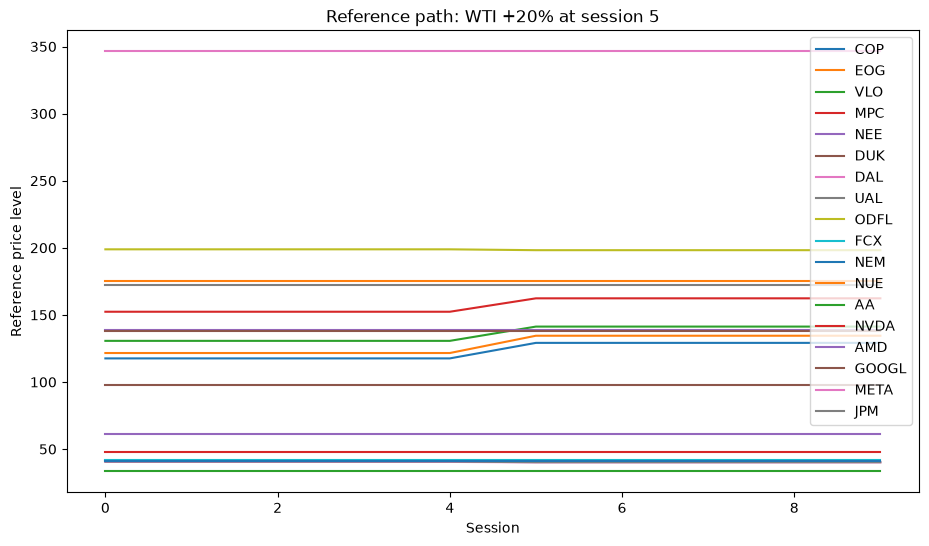

In [3]:
shock = pd.DataFrame(
    {node: np.full(10, 100.0) for node in external_nodes},
    index=pd.Index(range(10), name="session"),
)
if "wti" not in shock.columns:
    raise ValueError("real_v1 must include the wti external node")
shock.loc[5:, "wti"] = 120.0
reference = reference_path(graph, shock, mode="full")
ax = reference.plot(figsize=(11, 6), title="Reference path: WTI +20% at session 5")
ax.set_ylabel("Reference price level")
ax.set_xlabel("Session")
plt.show()

## Real 2024-2025 external scenario

Run this cell after the cleaned daily data are available. It writes the `EXTERNAL`-validated parquet via the data API.

In [4]:
path = build_real_2024_2025()
real = api.load_external("real_2024_2025")
print(f"{path.name}: {len(real)} sessions, {real['date'].min().date()} .. {real['date'].max().date()}")
real.head()

external_real_2024_2025.parquet: 502 sessions, 2024-01-02 .. 2025-12-31


,date,wti,henry_hub,copper,gold,sp500
session,,,,,,
0,2024-01-02,70.62,2.56,3.8690,2073.399902,4742.83
1,2024-01-03,72.97,2.57,3.8475,2042.800049,4704.81
2,2024-01-04,72.38,2.83,3.8310,2050.000000,4688.68
3,2024-01-05,74.00,2.75,3.7945,2049.800049,4697.24
4,2024-01-08,71.06,2.72,3.7995,2033.500000,4763.54
